# Lab 02 — TV4: Đánh giá kết quả Canny — Phúc

**Nhiệm vụ:** LAB2-TV4: Implement edge-map evaluation. Notebook độc lập, không cần chạy notebook TV1–TV3 trước.

**Câu hỏi:** OpenCV và scikit-image trùng khớp đến đâu, mất bao lâu trên cùng ảnh,
và các cấu hình ngưỡng thay đổi kết quả thế nào? Precision/Recall/F1 cần dữ liệu tham chiếu gì?

**Phạm vi:** 3 ảnh chung × 3 cấu hình × 2 thư viện. IoU trên ảnh chung chỉ đo sự đồng thuận
giữa hai bản đồ biên; không có ground truth nên chưa kết luận độ chính xác thực tế.
TP/FP/FN và Precision/Recall/F1 được minh họa bằng mask nhỏ có nhãn tự định nghĩa.

## 1. Môi trường và cách chạy

Từ repository root, dùng môi trường chung do TV6 chuẩn bị:

```powershell
python -m venv .venv
.venv/Scripts/python.exe -m pip install -r requirements.txt
.venv/Scripts/python.exe -m jupyter notebook
```

Chọn kernel dùng Python của `.venv`, mở notebook này, **Restart Kernel → Run All**.
Kernel có thể khởi động tại repository root hoặc `lab_2/notebook`.
Mọi đường dẫn dữ liệu được tạo từ vị trí repository; không chứa đường dẫn cá nhân cố định.
Chạy lại sẽ cập nhật bảng và hình trong thư mục riêng `lab_2/result/figures/tv4_evaluation/`.

In [1]:
from pathlib import Path
from time import perf_counter_ns
from datetime import datetime, timezone, timedelta
from html import escape
from importlib.metadata import version
import csv
import hashlib
import json
import platform

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from skimage.feature import canny
from IPython.display import display, HTML, Markdown

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / 'lab_2/data/input').is_dir()
                     and (p / 'requirements.txt').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Khởi động kernel tại repository root hoặc lab_2/notebook.')
INPUT_DIR = PROJECT_ROOT / 'lab_2/data/input'
RESULT_DIR = PROJECT_ROOT / 'lab_2/result/figures/tv4_evaluation'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'figure.dpi': 110, 'savefig.dpi': 160,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'OpenCV': '#24568A', 'scikit-image': '#D18A24'}
cv2.setNumThreads(1)  # Điều kiện benchmark cố định, không dùng số thread mặc định của máy.
cv2.ocl.setUseOpenCL(False)

environment = {
    'executed_at': datetime.now(timezone(timedelta(hours=7))).isoformat(timespec='seconds'),
    'python': platform.python_version(), 'platform': platform.platform(),
    'machine': platform.machine(), 'processor': platform.processor(),
    'packages': {p: version(p) for p in
                 ['numpy', 'opencv-python', 'scikit-image', 'matplotlib', 'nbformat', 'nbclient']},
    'opencv_threads': cv2.getNumThreads(), 'opencv_opencl': cv2.ocl.useOpenCL(),
    'input_dtype_cv': 'uint8', 'input_dtype_sk': 'float64 [0,1]',
    'timing_scope': 'Gaussian smoothing + Canny; exclude reading, conversion, plotting, saving',
}
(RESULT_DIR / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(json.dumps(environment, ensure_ascii=False, indent=2))

{
  "executed_at": "2026-10-13T21:30:13+07:00",
  "python": "3.11.9",
  "platform": "Windows-10-10.0.26200-SP0",
  "machine": "AMD64",
  "processor": "AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD",
  "packages": {
    "numpy": "2.4.6",
    "opencv-python": "5.0.0.93",
    "scikit-image": "0.26.0",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0"
  },
  "opencv_threads": 1,
  "opencv_opencl": false,
  "input_dtype_cv": "uint8",
  "input_dtype_sk": "float64 [0,1]",
  "timing_scope": "Gaussian smoothing + Canny; exclude reading, conversion, plotting, saving"
}


## 2. Định nghĩa chỉ số và quy ước

Mask nhị phân chấp nhận `bool`, số 0/1 hoặc 0/255; **pixel khác 0 là biên**.
Hai mask phải là mảng số/Boolean 2D không chứa NaN/Inf, cùng kích thước và có ít nhất một pixel.
Không tự resize, giãn biên hoặc bỏ đường viền trước khi đánh giá.

\[
IoU(A,B)=\frac{|A\cap B|}{|A\cup B|}
\]

Hai mask không có biên: quy ước IoU = 1 (hai tập rỗng giống nhau); một mask không có biên: IoU = 0.
Mảng có kích thước 0 khác với ảnh có pixel nhưng tất cả bằng 0: mảng kích thước 0 bị từ chối.

Khi có ground truth \(G\) và dự đoán \(P\):
\(TP=|P\cap G|\), \(FP=|P\setminus G|\), \(FN=|G\setminus P|\).

\[
Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN},\quad
F1=\frac{2TP}{2TP+FP+FN}
\]

Mẫu số bằng 0 trả `NaN` (không xác định), không tự thay bằng điểm hoàn hảo.
Đánh giá khớp **đúng pixel**, không có dung sai dịch chuyển; biên lệch 1 pixel có thể bị phạt mạnh.

In [2]:
def to_binary_mask(mask):
    """Return a new 2D bool mask; accept finite numeric values, nonzero = edge."""
    if not isinstance(mask, np.ndarray):
        raise TypeError('Mask phải là numpy.ndarray.')
    if mask.ndim != 2 or mask.size == 0:
        raise ValueError('Mask phải là mảng 2D có ít nhất một pixel.')
    if mask.dtype.kind not in 'buif':
        raise TypeError('Mask phải có dtype Boolean hoặc số thực/số nguyên.')
    if not np.isfinite(mask).all():
        raise ValueError('Mask không được chứa NaN hoặc Inf.')
    return mask != 0


def paired_masks(first, second):
    a, b = to_binary_mask(first), to_binary_mask(second)
    if a.shape != b.shape:
        raise ValueError(f'Mask khác kích thước: {a.shape} và {b.shape}.')
    return a, b


def binary_iou(first, second):
    a, b = paired_masks(first, second)
    intersection = np.count_nonzero(a & b)
    union = np.count_nonzero(a | b)
    return float(intersection / union) if union else 1.0


def edge_metrics(prediction, ground_truth):
    p, g = paired_masks(prediction, ground_truth)
    tp = int(np.count_nonzero(p & g))
    fp = int(np.count_nonzero(p & ~g))
    fn = int(np.count_nonzero(~p & g))
    tn = int(np.count_nonzero(~p & ~g))
    def ratio(numerator, denominator):
        return numerator / denominator if denominator else float('nan')
    return {'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Precision': ratio(tp, tp + fp), 'Recall': ratio(tp, tp + fn),
            'F1': ratio(2 * tp, 2 * tp + fp + fn), 'IoU': binary_iou(p, g)}


def benchmark_methods(methods, repeats=30, warmup=5, seed=20261013):
    """Warm up, then measure individual calls in reproducibly shuffled method order."""
    for name, count, minimum in [('repeats', repeats, 1), ('warmup', warmup, 0)]:
        if isinstance(count, bool) or not isinstance(count, int) or count < minimum:
            raise ValueError(f'{name} phải là số nguyên >= {minimum}.')
    if not methods or any(not callable(f) for f in methods.values()):
        raise ValueError('methods phải có ít nhất một hàm gọi được.')
    for function in methods.values():
        for _ in range(warmup):
            function()
    samples = {name: [] for name in methods}
    rng = np.random.default_rng(seed)
    names = list(methods)
    for _ in range(repeats):
        for index in rng.permutation(len(names)):
            name = names[index]
            start = perf_counter_ns()
            result = methods[name]()
            elapsed_ms = (perf_counter_ns() - start) / 1e6
            samples[name].append(elapsed_ms)
            del result  # Giải phóng kết quả nằm ngoài khoảng đo.
    summaries = {}
    for name, values in samples.items():
        q25, median, q75 = np.percentile(values, [25, 50, 75])
        summaries[name] = {'median_ms': float(median), 'q25_ms': float(q25),
                           'q75_ms': float(q75), 'mean_ms': float(np.mean(values)),
                           'repeats': repeats, 'warmup': warmup}
    return summaries, samples


def show_table(rows, columns=None):
    """Render a small HTML table without adding a pandas dependency."""
    columns = columns or list(rows[0])
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return 'N/A' if np.isnan(value) else f'{value:.4f}'
        return str(value)
    header = ''.join(f'<th>{escape(c)}</th>' for c in columns)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(fmt(row[c]))}</td>' for c in columns)
                   + '</tr>' for row in rows)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>' + header
                 + '</tr></thead><tbody>' + body + '</tbody></table></div>'))


def save_csv(name, rows):
    with (RESULT_DIR / name).open('w', encoding='utf-8-sig', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_figure(fig, name):
    fig.savefig(RESULT_DIR / name, bbox_inches='tight')
    plt.show()
    plt.close(fig)
print('Đã định nghĩa hàm mask, IoU, TP/FP/FN, benchmark và lưu bảng/hình.')

Đã định nghĩa hàm mask, IoU, TP/FP/FN, benchmark và lưu bảng/hình.


### 2.1. Kiểm thử độc lập bằng kết quả tính tay

Ví dụ có 5 pixel biên tham chiếu và 4 pixel dự đoán: TP=3, FP=1, FN=2.
Kết quả mong đợi: Precision=3/4, Recall=3/5, F1=6/9, IoU=3/6.
Kiểm thử thêm quy ước rỗng, lỗi đầu vào, tính đối xứng và input không bị sửa.

In [3]:
ground_truth = np.zeros((8, 8), dtype=bool)
ground_truth[2, 2:5] = True
ground_truth[3:5, 4] = True
prediction = np.zeros_like(ground_truth)
prediction[2, 2:4] = True
prediction[3, 4] = True
prediction[5, 5] = True
known = edge_metrics(prediction, ground_truth)
assert (known['TP'], known['FP'], known['FN'], known['TN']) == (3, 1, 2, 58)
assert np.isclose(known['Precision'], 0.75)
assert np.isclose(known['Recall'], 0.6)
assert np.isclose(known['F1'], 2 / 3)
assert np.isclose(known['IoU'], 0.5)
assert sum(known[k] for k in ['TP', 'FP', 'FN', 'TN']) == ground_truth.size

zero = np.zeros((8, 8), dtype=bool)
assert binary_iou(ground_truth, ground_truth) == 1
assert binary_iou(zero, zero) == 1
assert binary_iou(zero, ground_truth) == 0
assert binary_iou(prediction, ground_truth) == binary_iou(ground_truth, prediction)
assert binary_iou(prediction.astype(np.uint8) * 255, ground_truth) == 0.5
assert np.isnan(edge_metrics(zero, zero)['Precision'])
assert np.isnan(edge_metrics(zero, zero)['Recall'])
assert np.isnan(edge_metrics(zero, zero)['F1'])
assert edge_metrics(zero, ground_truth)['Recall'] == 0
assert edge_metrics(zero, ground_truth)['F1'] == 0
assert edge_metrics(ground_truth, zero)['Precision'] == 0

disjoint = np.zeros_like(ground_truth)
disjoint[7, :] = True
assert binary_iou(disjoint, ground_truth) == 0
before = prediction.copy()
edge_metrics(prediction, ground_truth)
assert np.array_equal(before, prediction)

invalid_cases = [
    ('khác kích thước', lambda: binary_iou(zero, np.zeros((2, 2))), ValueError),
    ('mảng kích thước 0', lambda: to_binary_mask(np.zeros((0, 2))), ValueError),
    ('mảng 3D', lambda: to_binary_mask(np.zeros((2, 2, 3))), ValueError),
    ('list thay ndarray', lambda: to_binary_mask([[0, 1]]), TypeError),
    ('NaN', lambda: to_binary_mask(np.array([[np.nan]])), ValueError),
    ('Inf', lambda: to_binary_mask(np.array([[np.inf]])), ValueError),
    ('dtype chuỗi', lambda: to_binary_mask(np.array([['0']])), TypeError),
    ('repeats=0', lambda: benchmark_methods({'dummy': lambda: None}, repeats=0), ValueError),
    ('warmup âm', lambda: benchmark_methods({'dummy': lambda: None}, warmup=-1), ValueError),
]
for label, function, expected_error in invalid_cases:
    try:
        function()
    except expected_error:
        pass
    else:
        raise AssertionError(f'Không báo lỗi mong đợi: {label}')
test_summary, test_samples = benchmark_methods({'dummy': lambda: 1}, repeats=3, warmup=1)
assert len(test_samples['dummy']) == 3 and test_summary['dummy']['median_ms'] >= 0
show_table([known])
print(f'Đạt kiểm thử số liệu tính tay, quy ước rỗng, bảo toàn input và {len(invalid_cases)} lỗi đầu vào.')

TP,FP,FN,TN,Precision,Recall,F1,IoU
3,1,2,58,0.7500,0.6000,0.6667,0.5000


Đạt kiểm thử số liệu tính tay, quy ước rỗng, bảo toàn input và 9 lỗi đầu vào.


## 3. Dữ liệu và nguồn tham chiếu

Dùng đúng 3 ảnh từ bộ dữ liệu TV6 đã đặt trong repository:

| Ảnh | Vai trò trong thí nghiệm |
|---|---|
| `01_hinh_hoc_ro_net.png` | Hình học rõ nét, quan sát sự lệch vị trí biên |
| `02_tuong_phan_thap.png` | Ảnh tương phản thấp, khảo sát ảnh hưởng ngưỡng |
| `04_anh_that_nhieu_chi_tiet.png` | Ảnh thật nhiều chi tiết, xem mức đồng thuận trên cấu trúc phức tạp |

Nguồn nội bộ: `lab_2/data/review data.md`, bộ dữ liệu trên `origin/main` tại commit
`cfd2dcaac2170ac2912dbfe523ba603b2fed7d42`.
Tài liệu dữ liệu chưa ghi đầy đủ nguồn gốc từng ảnh; notebook chỉ khẳng định nguồn lấy file là repository.
Không có ground-truth edge map được cung cấp cho 3 ảnh này.
Các biến thể trong bộ 50 ảnh không phải 50 cảnh độc lập; notebook không tổng hợp chúng như các mẫu độc lập.

Đọc file bằng byte và `cv2.imdecode` để hỗ trợ đường dẫn Unicode trên Windows.
Giữ kích thước gốc; chuyển BGR → grayscale một lần rồi tạo `float64 / 255` cho scikit-image.
SHA-256 được lưu để nhận diện chính xác dữ liệu khi chạy lại.

In [4]:
IMAGE_SPECS = [
    ('hinh_hoc', 'Hình học', '01_hinh_hoc_ro_net.png'),
    ('tuong_phan_thap', 'Tương phản thấp', '02_tuong_phan_thap.png'),
    ('nhieu_chi_tiet', 'Nhiều chi tiết', '04_anh_that_nhieu_chi_tiet.png'),
]
images, manifest = {}, []
for image_id, label, filename in IMAGE_SPECS:
    path = INPUT_DIR / filename
    raw = path.read_bytes()
    bgr = cv2.imdecode(np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise OSError(f'Không đọc được ảnh {filename}.')
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    images[image_id] = {'label': label, 'rgb': cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB),
                        'gray': gray, 'float': gray.astype(np.float64) / 255.0}
    manifest.append({'image': image_id, 'file': path.relative_to(PROJECT_ROOT).as_posix(),
                     'height': gray.shape[0], 'width': gray.shape[1],
                     'dtype': str(gray.dtype), 'min': int(gray.min()), 'max': int(gray.max()),
                     'sha256': hashlib.sha256(raw).hexdigest(), 'ground_truth': 'not provided'})
save_csv('input_manifest.csv', manifest)
show_table(manifest, ['image', 'file', 'height', 'width', 'dtype', 'min', 'max', 'ground_truth'])

image,file,height,width,dtype,min,max,ground_truth
hinh_hoc,lab_2/data/input/01_hinh_hoc_ro_net.png,512,512,uint8,15,245,not provided
tuong_phan_thap,lab_2/data/input/02_tuong_phan_thap.png,512,512,uint8,112,143,not provided
nhieu_chi_tiet,lab_2/data/input/04_anh_that_nhieu_chi_tiet.png,512,512,uint8,0,255,not provided


## 4. Cấu hình và cách so sánh

**Cấu hình cơ sở của bài:** Gaussian sigma=1.0, OpenCV ngưỡng 50/150,
apertureSize=3, L2gradient=True; scikit-image ngưỡng 50/255 và 150/255,
use_quantiles=False. Cách chọn này tham khảo notebook TV1 trong repo, nhưng tự chạy lại toàn bộ ở đây.
Đây là cấu hình cơ sở tự chọn, **không phải bộ mặc định chung của hai thư viện**.

Hai cấu hình còn lại chỉ thay ngưỡng: thấp 20/60 và cao 100/200 (OpenCV),
tương ứng chia 255 khi truyền ảnh float [0,1] cho scikit-image. Sigma giữ nguyên.
Việc chia 255 chỉ đổi thang cường độ, **không hiệu chuẩn hai phép tính gradient thành tương đương**.

OpenCV: làm mờ Gaussian kernel 9×9 (bán kính 4 sigma), border reflect, rồi `cv2.Canny`.
scikit-image: gọi `canny` trên ảnh float gốc với sigma=1, mode='reflect'; thư viện tự làm mờ.
Không làm mờ trước rồi để scikit-image làm mờ thêm lần nữa.

Khác biệt có thể đến từ độ chính xác uint8/float, scale gradient, nội suy non-maximum suppression
và xử lý đường viền. IoU exact-pixel được tính trên toàn ảnh, không bỏ vùng khó so sánh.
Nguyên nhân cụ thể của từng pixel sai khác chưa được kiểm chứng chỉ bằng IoU.

Tài liệu chính thức:
[OpenCV Canny](https://docs.opencv.org/4.13.0/dd/d1a/group__imgproc__feature.html)
(tham số ngưỡng, aperture, chuẩn gradient),
[scikit-image Canny](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.canny)
(sigma, ngưỡng, smoothing và non-maximum suppression).
Phiên bản thực thi nằm trong `environment.json`; URL tài liệu OpenCV 4.13 có thể khác phiên bản đã cài.

In [5]:
SIGMA = 1.0
KERNEL_SIZE = 2 * int(np.ceil(4 * SIGMA)) + 1
CONFIGS = [
    {'id': 'co_so', 'label': 'Cơ sở', 'cv_low': 50, 'cv_high': 150},
    {'id': 'nguong_thap', 'label': 'Ngưỡng thấp', 'cv_low': 20, 'cv_high': 60},
    {'id': 'nguong_cao', 'label': 'Ngưỡng cao', 'cv_low': 100, 'cv_high': 200},
]
for config in CONFIGS:
    config.update({'sigma': SIGMA, 'cv_kernel': KERNEL_SIZE, 'aperture': 3,
                   'L2gradient': True, 'sk_low': config['cv_low'] / 255.0,
                   'sk_high': config['cv_high'] / 255.0, 'sk_mode': 'reflect',
                   'use_quantiles': False})
save_csv('configurations.csv', CONFIGS)
show_table(CONFIGS, ['id', 'sigma', 'cv_kernel', 'cv_low', 'cv_high', 'aperture',
                    'L2gradient', 'sk_low', 'sk_high', 'sk_mode'])


def opencv_pipeline(gray, config):
    blurred = cv2.GaussianBlur(gray, (config['cv_kernel'], config['cv_kernel']),
                               config['sigma'], borderType=cv2.BORDER_REFLECT)
    return cv2.Canny(blurred, config['cv_low'], config['cv_high'],
                     apertureSize=config['aperture'], L2gradient=config['L2gradient'])


def skimage_pipeline(gray_float, config):
    return canny(gray_float, sigma=config['sigma'], low_threshold=config['sk_low'],
                 high_threshold=config['sk_high'], use_quantiles=config['use_quantiles'],
                 mode=config['sk_mode'])

id,sigma,cv_kernel,cv_low,cv_high,aperture,L2gradient,sk_low,sk_high,sk_mode
co_so,1.0000,9,50,150,3,True,0.1961,0.5882,reflect
nguong_thap,1.0000,9,20,60,3,True,0.0784,0.2353,reflect
nguong_cao,1.0000,9,100,200,3,True,0.3922,0.7843,reflect


## 5. Chạy 3 ảnh × 3 cấu hình và đo thời gian

Mỗi phương pháp khởi động **5 lần** trước khi đo **30 lần** bằng `perf_counter_ns`.
Trong mỗi vòng, thứ tự hai thư viện được xáo trộn với seed cố định để giảm thiên lệch thứ tự.
Khoảng đo bao gồm **làm mờ Gaussian và Canny** cho cả hai; loại trừ đọc ảnh,
chuyển ảnh xám/float, chuyển mask Boolean, tính chỉ số, vẽ và ghi file.

OpenCV chạy CPU một thread và tắt OpenCL; không suy rộng kết quả này thành tốc độ mặc định
trên mọi máy. Median là thời gian điển hình; Q25–Q75 là độ phân tán quan sát qua 30 lần chạy,
không phải khoảng tin cậy thống kê. Máy bận có thể làm thời gian thay đổi khi chạy lại.

In [6]:
results, raw_timings, edge_maps = [], [], {}
for image_index, (image_id, label, filename) in enumerate(IMAGE_SPECS):
    image = images[image_id]
    gray_before = image['gray'].copy()
    for config_index, config in enumerate(CONFIGS):
        methods = {
            'OpenCV': lambda image=image, config=config: opencv_pipeline(image['gray'], config),
            'scikit-image': lambda image=image, config=config: skimage_pipeline(image['float'], config),
        }
        edges_cv = to_binary_mask(methods['OpenCV']())
        edges_sk = to_binary_mask(methods['scikit-image']())
        assert edges_cv.shape == edges_sk.shape == image['gray'].shape
        edge_maps[(image_id, config['id'])] = {'OpenCV': edges_cv, 'scikit-image': edges_sk}
        timing, samples = benchmark_methods(methods, repeats=30, warmup=5,
                                            seed=20261013 + 10 * image_index + config_index)
        intersection = int(np.count_nonzero(edges_cv & edges_sk))
        union = int(np.count_nonzero(edges_cv | edges_sk))
        row = {'image': image_id, 'config': config['id'],
               'height': edges_cv.shape[0], 'width': edges_cv.shape[1],
               'sigma': config['sigma'], 'cv_low': config['cv_low'], 'cv_high': config['cv_high'],
               'sk_low': config['sk_low'], 'sk_high': config['sk_high'],
               'cv_edges': int(edges_cv.sum()), 'sk_edges': int(edges_sk.sum()),
               'intersection': intersection, 'union': union,
               'both_empty': union == 0, 'iou_cv_sk': binary_iou(edges_cv, edges_sk)}
        for method, prefix in [('OpenCV', 'cv'), ('scikit-image', 'sk')]:
            row.update({f'{prefix}_{key}': value for key, value in timing[method].items()})
            for iteration, elapsed in enumerate(samples[method], start=1):
                raw_timings.append({'image': image_id, 'config': config['id'], 'method': method,
                                    'iteration': iteration, 'elapsed_ms': elapsed})
        results.append(row)
    assert np.array_equal(gray_before, image['gray']), 'Pipeline đã sửa ảnh đầu vào.'

assert len(results) == 9 and len(raw_timings) == 540
assert all(0 <= row['iou_cv_sk'] <= 1 for row in results)
assert all(row['cv_median_ms'] > 0 and row['sk_median_ms'] > 0 for row in results)
save_csv('comparison_results.csv', results)
save_csv('timing_samples.csv', raw_timings)
show_table(results, ['image', 'config', 'cv_low', 'cv_high', 'sk_low', 'sk_high',
                     'cv_edges', 'sk_edges', 'both_empty', 'iou_cv_sk', 'cv_median_ms', 'sk_median_ms'])
print('9 hàng kết quả; 540 lần đo có thời gian, không tính các lần khởi động.')

image,config,cv_low,cv_high,sk_low,sk_high,cv_edges,sk_edges,both_empty,iou_cv_sk,cv_median_ms,sk_median_ms
hinh_hoc,co_so,50,150,0.1961,0.5882,3134,3166,False,0.7176,0.6662,14.4868
hinh_hoc,nguong_thap,20,60,0.0784,0.2353,3137,3166,False,0.7170,0.7042,15.0984
hinh_hoc,nguong_cao,100,200,0.3922,0.7843,3132,3165,False,0.7177,0.6880,14.4380
tuong_phan_thap,co_so,50,150,0.1961,0.5882,0,0,True,1.0000,0.6197,14.0636
tuong_phan_thap,nguong_thap,20,60,0.0784,0.2353,1044,1011,False,0.9628,0.6326,14.0968
tuong_phan_thap,nguong_cao,100,200,0.3922,0.7843,0,0,True,1.0000,0.6185,13.3990
nhieu_chi_tiet,co_so,50,150,0.1961,0.5882,7936,7554,False,0.8694,0.9026,15.0428
nhieu_chi_tiet,nguong_thap,20,60,0.0784,0.2353,26624,25863,False,0.7953,1.4046,16.4019
nhieu_chi_tiet,nguong_cao,100,200,0.3922,0.7843,6025,5836,False,0.8956,0.8081,14.6358


9 hàng kết quả; 540 lần đo có thời gian, không tính các lần khởi động.


### 5.1. Bản đồ biên ở cấu hình cơ sở

Cột overlay phân biệt biên trùng nhau, chỉ OpenCV và chỉ scikit-image.
Những nhóm này là **sự khác biệt giữa phương pháp**, không phải TP/FP/FN vì chưa có nhãn thật.
Số pixel từng nhóm được ghi trong hình để không chỉ dựa vào màu.

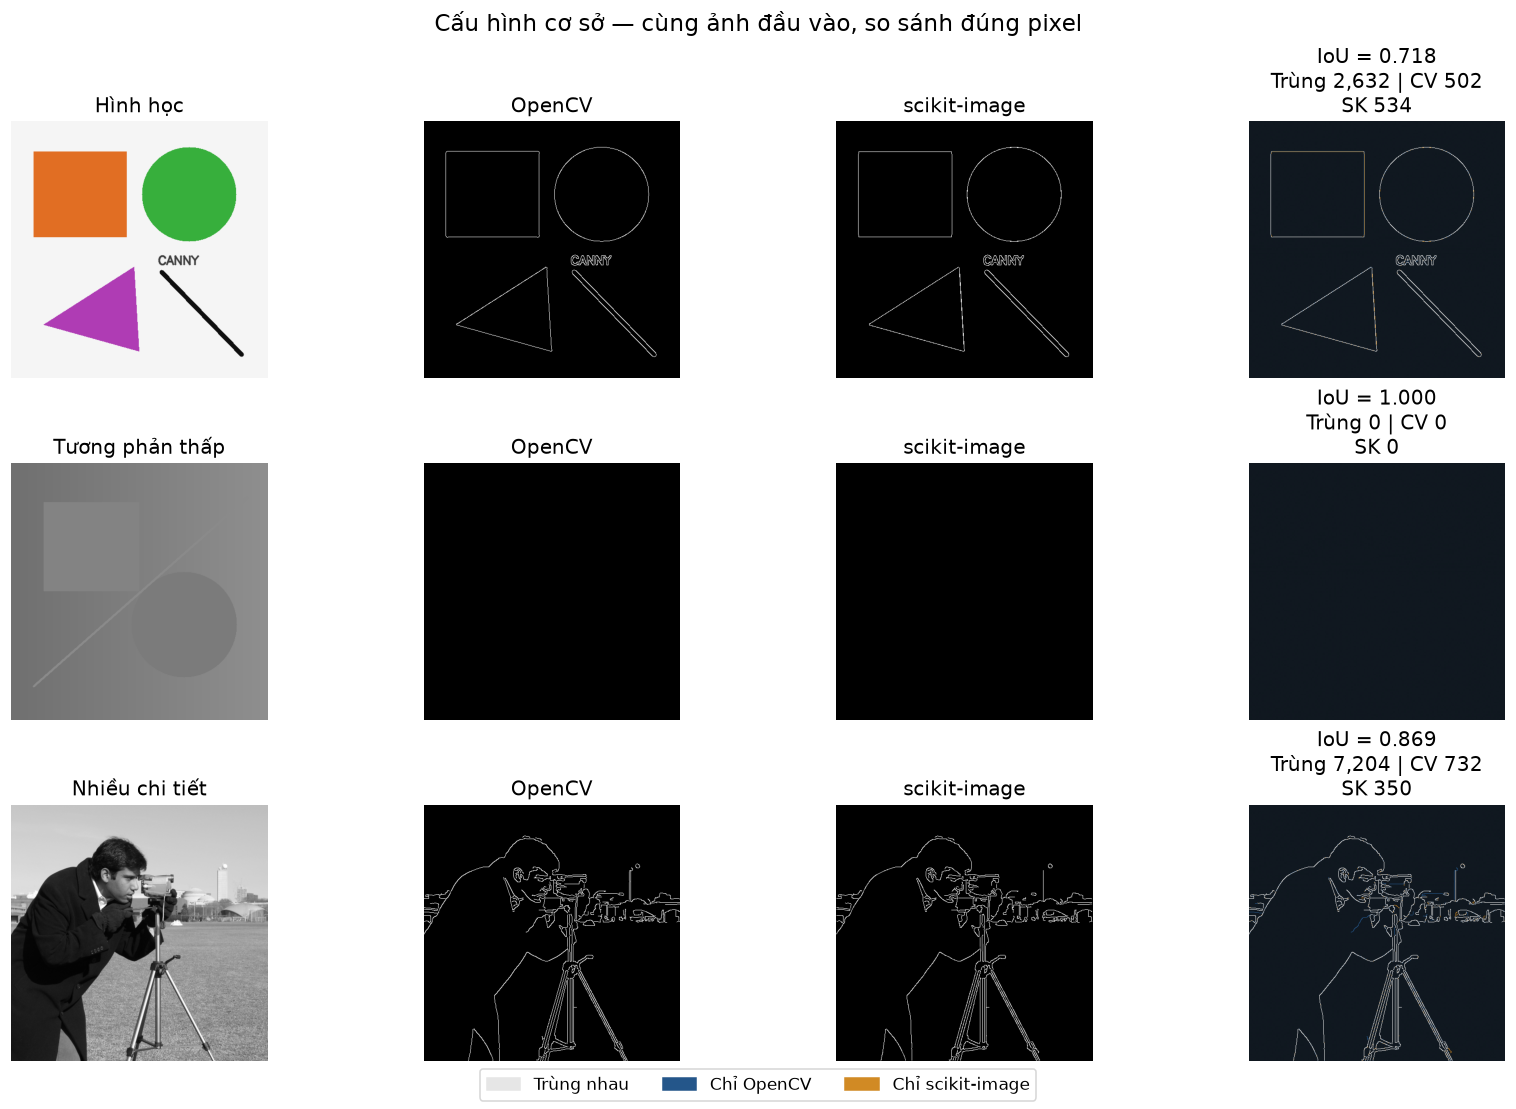

Các pixel chỉ xuất hiện ở một phương pháp chưa thể gọi là biên sai. IoU được đo toàn ảnh, kể cả đường viền.

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10), layout='constrained')
overlay_colors = ['#101820', '#E6E6E6', COLORS['OpenCV'], COLORS['scikit-image']]
overlay_cmap = ListedColormap(overlay_colors)
overlay_norm = BoundaryNorm(np.arange(-0.5, 4.5), 4)
for row_index, (image_id, label, _) in enumerate(IMAGE_SPECS):
    maps = edge_maps[(image_id, 'co_so')]
    a, b = maps['OpenCV'], maps['scikit-image']
    overlay = np.zeros(a.shape, dtype=np.uint8)
    overlay[a & b] = 1
    overlay[a & ~b] = 2
    overlay[~a & b] = 3
    panels = [(images[image_id]['rgb'], label), (a, 'OpenCV'), (b, 'scikit-image')]
    for col, (array, title) in enumerate(panels):
        axes[row_index, col].imshow(array, cmap='gray', vmin=0, vmax=1 if col else 255)
        axes[row_index, col].set_title(title)
    axes[row_index, 3].imshow(overlay, cmap=overlay_cmap, norm=overlay_norm)
    axes[row_index, 3].set_title(f'IoU = {binary_iou(a, b):.3f}\n'
                                f'Trùng {np.count_nonzero(a & b):,} | CV {np.count_nonzero(a & ~b):,}\n'
                                f'SK {np.count_nonzero(~a & b):,}')
    for axis in axes[row_index]:
        axis.axis('off')
fig.suptitle('Cấu hình cơ sở — cùng ảnh đầu vào, so sánh đúng pixel', fontsize=15)
fig.legend(handles=[Patch(color=overlay_colors[1], label='Trùng nhau'),
                    Patch(color=overlay_colors[2], label='Chỉ OpenCV'),
                    Patch(color=overlay_colors[3], label='Chỉ scikit-image')],
           loc='outside lower center', ncol=3)
save_figure(fig, '01_baseline_edge_comparison.png')
display(Markdown('Các pixel chỉ xuất hiện ở một phương pháp chưa thể gọi là biên sai. '
                 'IoU được đo toàn ảnh, kể cả đường viền.'))

### 5.2. So sánh ba cấu hình trên hai ảnh

Lưới giữ nguyên ảnh, sigma, kernel, aperture và chuẩn gradient; mỗi cột đổi cặp ngưỡng.
Số pixel biên mô tả lượng biên giữ lại, không phải số vật thể hay độ chính xác.

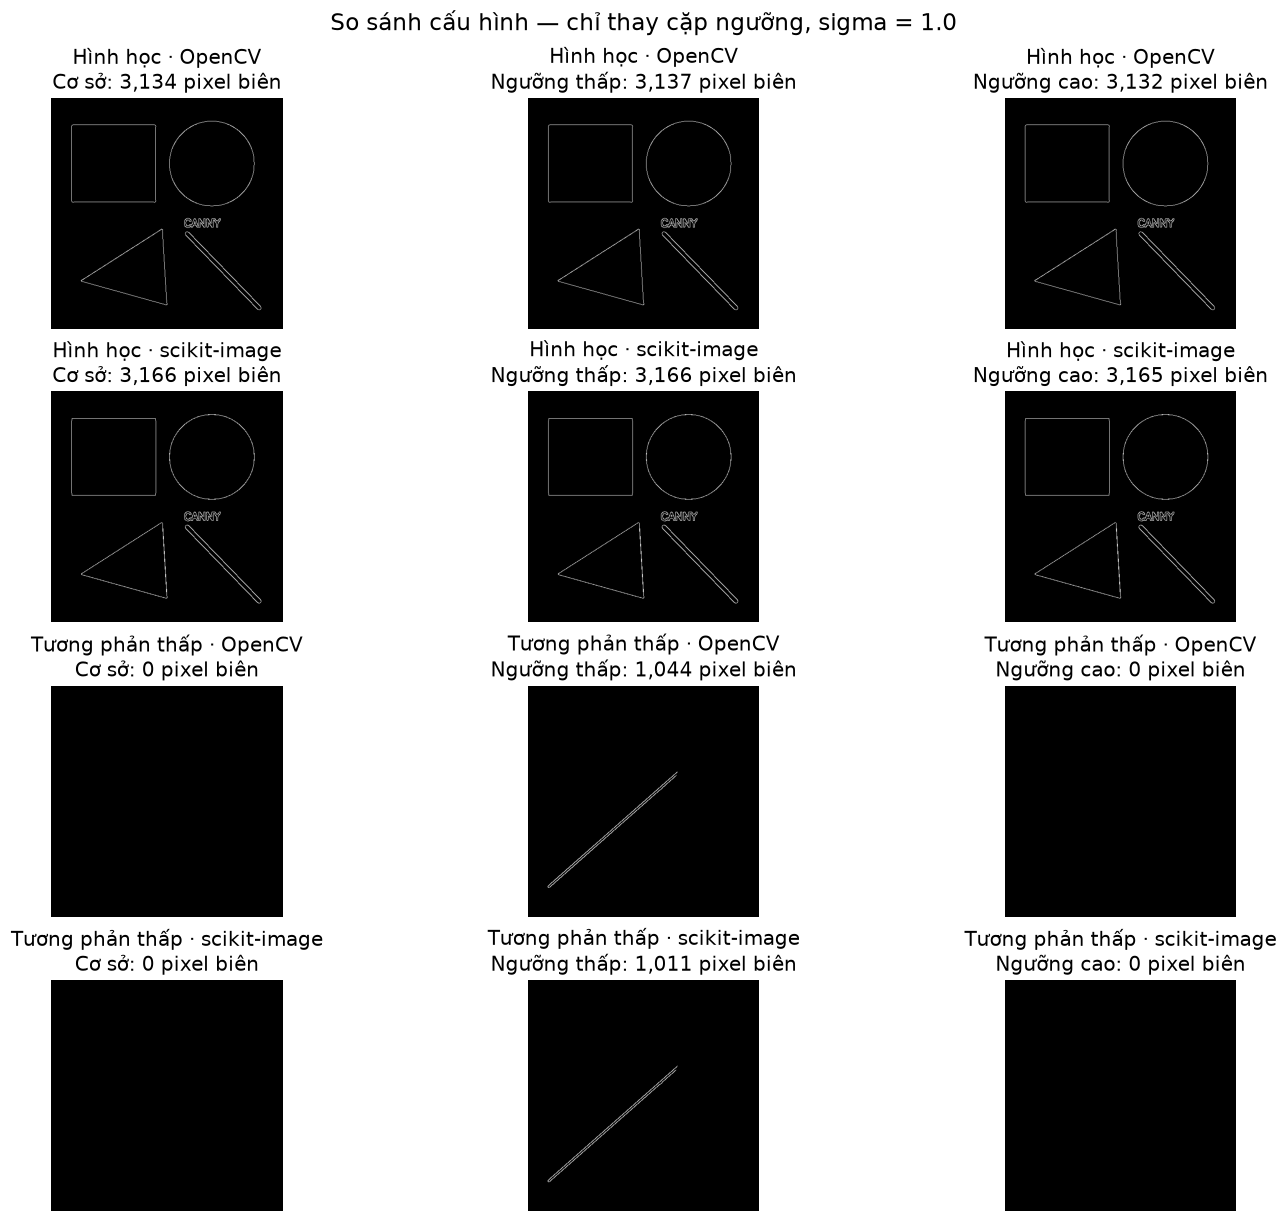

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(13, 11), layout='constrained')
for image_index, (image_id, label, _) in enumerate(IMAGE_SPECS[:2]):
    for method_index, method in enumerate(['OpenCV', 'scikit-image']):
        row_index = 2 * image_index + method_index
        for col, config in enumerate(CONFIGS):
            mask = edge_maps[(image_id, config['id'])][method]
            axes[row_index, col].imshow(mask, cmap='gray', vmin=0, vmax=1)
            axes[row_index, col].set_title(f'{label} · {method}\n{config["label"]}: {mask.sum():,} pixel biên')
            axes[row_index, col].axis('off')
fig.suptitle('So sánh cấu hình — chỉ thay cặp ngưỡng, sigma = 1.0', fontsize=15)
save_figure(fig, '02_threshold_configuration_grid.png')

### 5.3. IoU giữa hai thư viện và so với cấu hình cơ sở

Ngoài IoU OpenCV–scikit-image, tính IoU mỗi biến thể với **kết quả cơ sở của cùng thư viện**.
Kết quả cơ sở là tham chiếu thí nghiệm, không phải ground truth. Chênh lệch pixel biên
cho biết ngưỡng giữ thêm/bỏ bớt bao nhiêu pixel; không cho biết chất lượng tốt lên hay xấu đi.

image,config,method,iou_vs_baseline,edge_count,delta_edges_vs_baseline
hinh_hoc,co_so,OpenCV,1.0000,3134,0
hinh_hoc,co_so,scikit-image,1.0000,3166,0
hinh_hoc,nguong_thap,OpenCV,0.9990,3137,3
hinh_hoc,nguong_thap,scikit-image,1.0000,3166,0
hinh_hoc,nguong_cao,OpenCV,0.9994,3132,-2
hinh_hoc,nguong_cao,scikit-image,0.9997,3165,-1
tuong_phan_thap,co_so,OpenCV,1.0000,0,0
tuong_phan_thap,co_so,scikit-image,1.0000,0,0
tuong_phan_thap,nguong_thap,OpenCV,0.0000,1044,1044
tuong_phan_thap,nguong_thap,scikit-image,0.0000,1011,1011


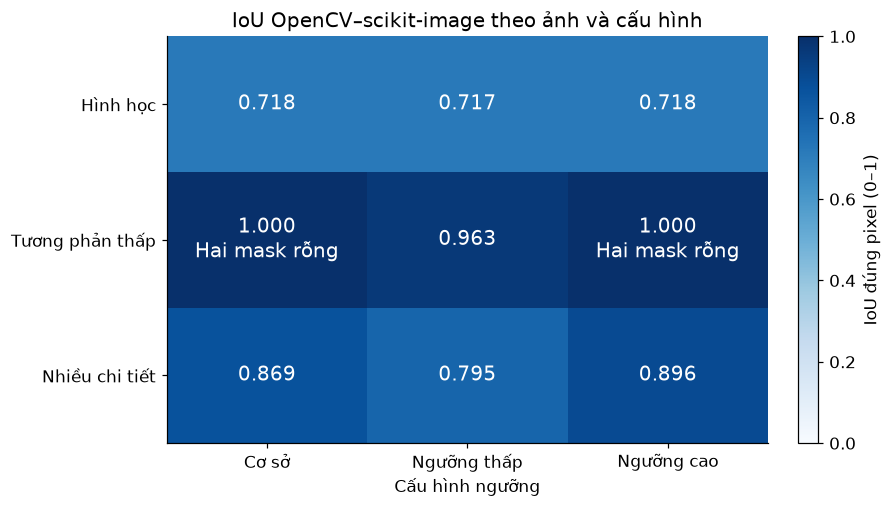

IoU giữa hai thư viện trong 9 cặp nằm trong khoảng **0.717–1.000**; **2 cặp có cả hai mask rỗng** nên IoU=1 theo quy ước. Không dùng các điểm 1 này làm bằng chứng phát hiện biên tốt. Đây là mức đồng thuận, không phải độ chính xác.

In [9]:
baseline_comparisons = []
for image_id, _, _ in IMAGE_SPECS:
    for config in CONFIGS:
        for method in ['OpenCV', 'scikit-image']:
            base = edge_maps[(image_id, 'co_so')][method]
            current = edge_maps[(image_id, config['id'])][method]
            baseline_comparisons.append({'image': image_id, 'config': config['id'], 'method': method,
                                         'reference': 'co_so same method; not ground truth',
                                         'iou_vs_baseline': binary_iou(current, base),
                                         'edge_count': int(current.sum()),
                                         'delta_edges_vs_baseline': int(current.sum()) - int(base.sum())})
save_csv('baseline_comparison.csv', baseline_comparisons)
show_table(baseline_comparisons, ['image', 'config', 'method', 'iou_vs_baseline',
                                 'edge_count', 'delta_edges_vs_baseline'])

iou_matrix = np.array([[next(r['iou_cv_sk'] for r in results
                            if r['image'] == image_id and r['config'] == config['id'])
                        for config in CONFIGS] for image_id, _, _ in IMAGE_SPECS])
fig, axis = plt.subplots(figsize=(8, 4.5), layout='constrained')
plot = axis.imshow(iou_matrix, cmap='Blues', vmin=0, vmax=1, aspect='auto')
axis.set_xticks(range(3), [c['label'] for c in CONFIGS])
axis.set_yticks(range(3), [label for _, label, _ in IMAGE_SPECS])
axis.set_xlabel('Cấu hình ngưỡng')
axis.set_title('IoU OpenCV–scikit-image theo ảnh và cấu hình')
for row_index in range(3):
    for col in range(3):
        value = iou_matrix[row_index, col]
        result_row = next(r for r in results if r['image'] == IMAGE_SPECS[row_index][0]
                          and r['config'] == CONFIGS[col]['id'])
        text = f'{value:.3f}' + ('\nHai mask rỗng' if result_row['both_empty'] else '')
        axis.text(col, row_index, text, ha='center', va='center',
                  color='white' if value > 0.6 else '#202020', fontsize=13)
fig.colorbar(plot, ax=axis, label='IoU đúng pixel (0–1)')
save_figure(fig, '03_iou_by_image_configuration.png')
empty_pairs = sum(r['both_empty'] for r in results)
display(Markdown(f'IoU giữa hai thư viện trong 9 cặp nằm trong khoảng '
                 f'**{iou_matrix.min():.3f}–{iou_matrix.max():.3f}**; '
                 f'**{empty_pairs} cặp có cả hai mask rỗng** nên IoU=1 theo quy ước. '
                 'Không dùng các điểm 1 này làm bằng chứng phát hiện biên tốt. '
                 'Đây là mức đồng thuận, không phải độ chính xác.'))

### 5.4. Thời gian toàn pipeline làm mờ và Canny

Ba biểu đồ dùng cùng trục thời gian tuyến tính bắt đầu từ 0.
Cột là median; thanh sai số là Q25–Q75 qua 30 lần chạy, không phải khoảng tin cậy.

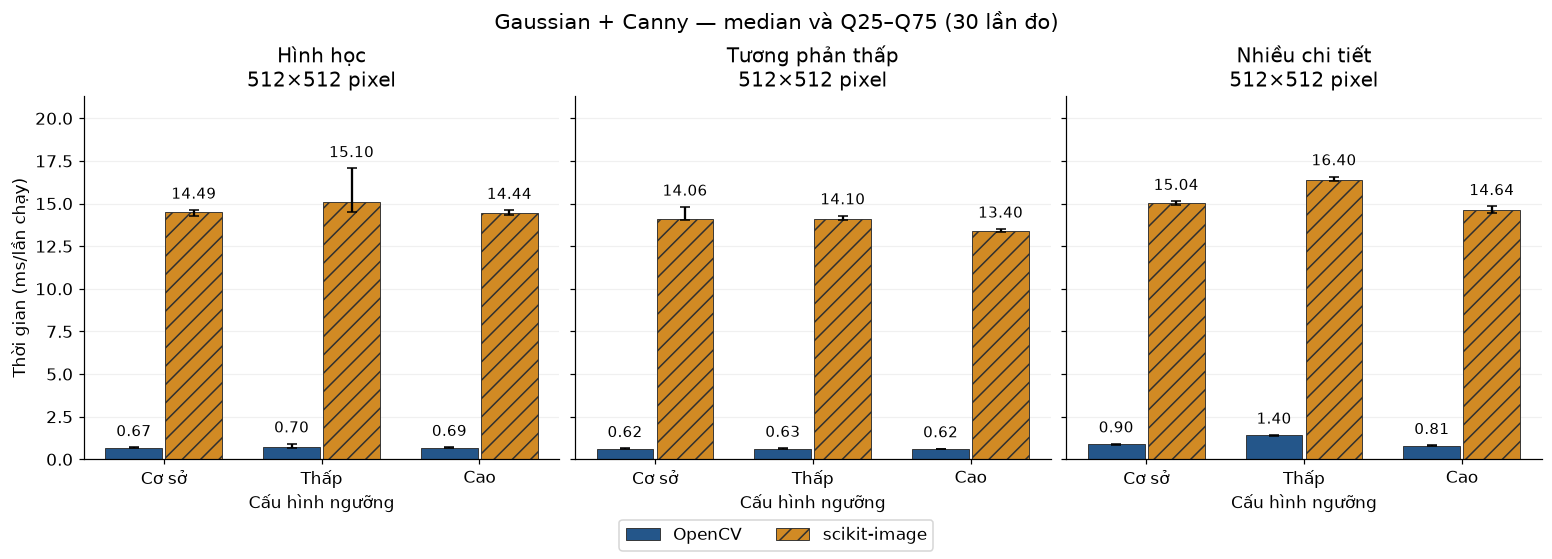

image,config,cv_median_ms,cv_q25_ms,cv_q75_ms,sk_median_ms,sk_q25_ms,sk_q75_ms
hinh_hoc,co_so,0.6662,0.6501,0.6975,14.4868,14.2753,14.6228
hinh_hoc,nguong_thap,0.7042,0.6719,0.9152,15.0984,14.4745,17.0596
hinh_hoc,nguong_cao,0.6880,0.6731,0.7085,14.4380,14.3292,14.6103
tuong_phan_thap,co_so,0.6197,0.6115,0.6423,14.0636,14.0142,14.8013
tuong_phan_thap,nguong_thap,0.6326,0.6166,0.6541,14.0968,14.0140,14.2921
tuong_phan_thap,nguong_cao,0.6185,0.6032,0.6293,13.3990,13.3295,13.5111
nhieu_chi_tiet,co_so,0.9026,0.8673,0.9157,15.0428,14.9248,15.1364
nhieu_chi_tiet,nguong_thap,1.4046,1.3474,1.4296,16.4019,16.3315,16.5821
nhieu_chi_tiet,nguong_cao,0.8081,0.7826,0.8196,14.6358,14.4586,14.8347


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), layout='constrained', sharey=True)
x = np.arange(3)
for axis, (image_id, label, _) in zip(axes, IMAGE_SPECS):
    rows = [next(r for r in results if r['image'] == image_id and r['config'] == c['id'])
            for c in CONFIGS]
    for method, prefix, offset, hatch in [('OpenCV', 'cv', -0.19, ''),
                                          ('scikit-image', 'sk', 0.19, '//')]:
        medians = np.array([r[f'{prefix}_median_ms'] for r in rows])
        q25 = np.array([r[f'{prefix}_q25_ms'] for r in rows])
        q75 = np.array([r[f'{prefix}_q75_ms'] for r in rows])
        bars = axis.bar(x + offset, medians, width=0.36, color=COLORS[method],
                        edgecolor='#303030', linewidth=0.6, hatch=hatch, label=method,
                        yerr=np.array([medians - q25, q75 - medians]), capsize=3)
        axis.bar_label(bars, labels=[f'{v:.2f}' for v in medians], padding=5, fontsize=10)
    axis.set_xticks(x, ['Cơ sở', 'Thấp', 'Cao'])
    axis.set_title(f'{label}\n{images[image_id]["gray"].shape[1]}×{images[image_id]["gray"].shape[0]} pixel')
    axis.set_xlabel('Cấu hình ngưỡng')
    axis.set_ylim(bottom=0)
    axis.grid(axis='y', alpha=0.18)
    axis.set_axisbelow(True)
axes[0].set_ylabel('Thời gian (ms/lần chạy)')
max_q75 = max(max(r['cv_q75_ms'], r['sk_q75_ms']) for r in results)
axes[0].set_ylim(0, max_q75 * 1.25)
fig.suptitle('Gaussian + Canny — median và Q25–Q75 (30 lần đo)', fontsize=14)
fig.legend(handles=axes[0].get_legend_handles_labels()[0],
           labels=['OpenCV', 'scikit-image'], loc='outside lower center', ncol=2)
save_figure(fig, '04_pipeline_timing.png')
show_table(results, ['image', 'config', 'cv_median_ms', 'cv_q25_ms', 'cv_q75_ms',
                     'sk_median_ms', 'sk_q25_ms', 'sk_q75_ms'])

## 6. Minh họa TP/FP/FN và độ nhạy với lệch vị trí

Ground truth dưới đây là mask 8×8 **do người viết tự định nghĩa trong mục 2.1**;
mask dự đoán được tạo thủ công để có TP/FP/FN đã biết, không phải output Canny trên ảnh thật.
Mỗi ô là một pixel; bảng có cả TN để đối chiếu tổng 64 pixel.
Không dùng accuracy làm chỉ số chính vì số pixel nền có thể áp đảo số pixel biên.

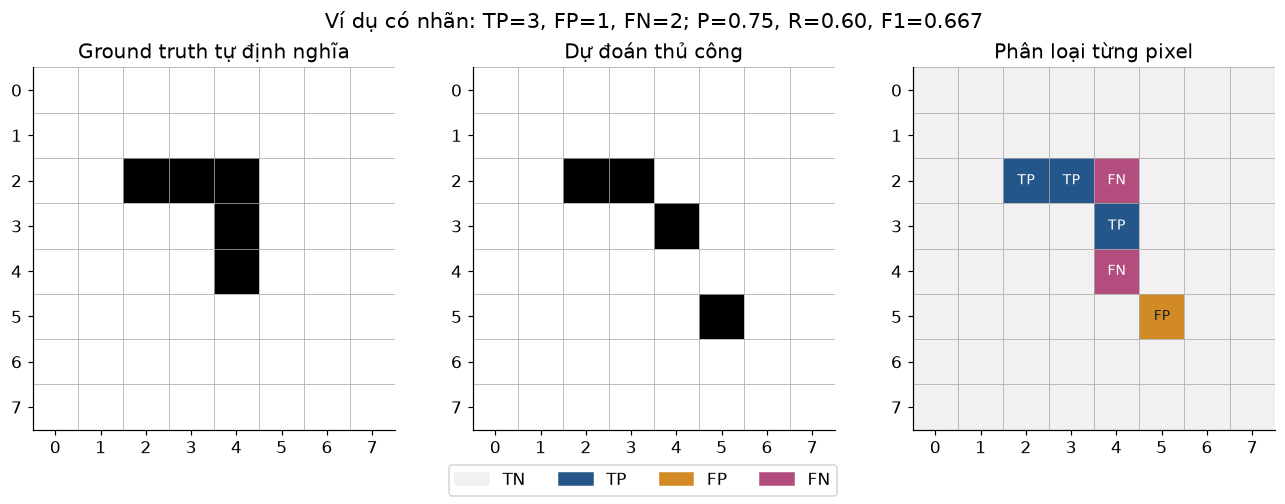

TP,FP,FN,TN,Precision,Recall,F1,IoU
3,1,2,58,0.7500,0.6000,0.6667,0.5000


**Giới hạn khớp đúng pixel:** hai đường thẳng 6 pixel giống hình dạng nhưng dịch ngang 1 pixel có IoU=0. Điều này giúp giải thích vì sao IoU có thể thấp dù biên nhìn gần nhau. Notebook không dùng giãn mask để làm tăng IoU; nếu bổ sung dung sai cần định nghĩa quy tắc matching riêng.

In [11]:
metrics_demo = edge_metrics(prediction, ground_truth)
save_csv('labeled_example_metrics.csv', [{'source': 'manual 8x8 masks; not real-image Canny', **metrics_demo}])
category = np.zeros(ground_truth.shape, dtype=np.uint8)
category[prediction & ground_truth] = 1
category[prediction & ~ground_truth] = 2
category[~prediction & ground_truth] = 3
category_colors = ['#F1F1F1', '#24568A', '#D18A24', '#B24D7E']
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout='constrained')
for axis, array, title in zip(axes, [ground_truth, prediction, category],
                             ['Ground truth tự định nghĩa', 'Dự đoán thủ công', 'Phân loại từng pixel']):
    if title == 'Phân loại từng pixel':
        axis.imshow(array, cmap=ListedColormap(category_colors),
                    norm=BoundaryNorm(np.arange(-0.5, 4.5), 4))
        for i, j in np.ndindex(array.shape):
            if array[i, j]:
                axis.text(j, i, ['TN', 'TP', 'FP', 'FN'][array[i, j]], ha='center', va='center',
                          color='white' if array[i, j] != 2 else '#202020', fontsize=9)
    else:
        axis.imshow(array, cmap='gray_r', vmin=0, vmax=1)
    axis.set_title(title)
    axis.set_xticks(range(8))
    axis.set_yticks(range(8))
    axis.set_xticks(np.arange(-0.5, 8), minor=True)
    axis.set_yticks(np.arange(-0.5, 8), minor=True)
    axis.grid(which='minor', color='#aaaaaa', linewidth=0.5)
    axis.tick_params(which='minor', bottom=False, left=False)
fig.suptitle('Ví dụ có nhãn: TP=3, FP=1, FN=2; P=0.75, R=0.60, F1=0.667', fontsize=14)
fig.legend(handles=[Patch(color=color, label=name) for color, name in
                    zip(category_colors, ['TN', 'TP', 'FP', 'FN'])],
           loc='outside lower center', ncol=4)
save_figure(fig, '05_labeled_tp_fp_fn_example.png')
show_table([metrics_demo])

line_a = np.zeros((8, 8), dtype=bool)
line_b = np.zeros_like(line_a)
line_a[1:7, 3] = True
line_b[1:7, 4] = True
assert binary_iou(line_a, line_b) == 0
display(Markdown('**Giới hạn khớp đúng pixel:** hai đường thẳng 6 pixel giống hình dạng '
                 'nhưng dịch ngang 1 pixel có IoU=0. Điều này giúp giải thích vì sao '
                 'IoU có thể thấp dù biên nhìn gần nhau. Notebook không dùng giãn mask '
                 'để làm tăng IoU; nếu bổ sung dung sai cần định nghĩa quy tắc matching riêng.'))

## 7. Kết luận và bàn giao

Các nhận xét dưới đây được tạo từ kết quả vừa chạy, không điền sẵn số liệu.
Thời gian có thể thay đổi giữa các lần chạy; chỉ kết luận trong phạm vi dữ liệu,
cấu hình, phiên bản và điều kiện CPU đã ghi nhận.

In [12]:
nonempty_results = [r for r in results if not r['both_empty']]
best = max(nonempty_results, key=lambda r: r['iou_cv_sk']) if nonempty_results else None
worst = min(nonempty_results, key=lambda r: r['iou_cv_sk']) if nonempty_results else None
cv_faster = sum(r['cv_median_ms'] < r['sk_median_ms'] for r in results)
labels = {image_id: label for image_id, label, _ in IMAGE_SPECS}
conclusions = [
    f'Đã chạy 3 ảnh × 3 cấu hình × 2 thư viện, thu 9 cặp bản đồ biên và 540 mẫu thời gian.',
    (f'Trong các cặp không đồng thời rỗng, IoU cao nhất là {best["iou_cv_sk"]:.3f} '
    f'ở {labels[best["image"]]} / {best["config"]}; '
    f'thấp nhất là {worst["iou_cv_sk"]:.3f} ở {labels[worst["image"]]} / {worst["config"]}. '
    f'Có {empty_pairs} cặp đồng thời rỗng cho IoU=1 theo quy ước, không chứng minh phát hiện đúng biên.'
    if best else 'Mọi cặp đều rỗng; chưa thể kết luận sự đồng thuận trên các pixel biên.'),
    f'Median pipeline OpenCV thấp hơn scikit-image ở {cv_faster}/9 trường hợp, '
    'trong điều kiện CPU một thread cho OpenCV, tắt OpenCL và bao gồm làm mờ cho cả hai.',
]
for image_id, label, _ in IMAGE_SPECS:
    counts = {method: [int(edge_maps[(image_id, c['id'])][method].sum()) for c in CONFIGS]
              for method in ['OpenCV', 'scikit-image']}
    conclusions.append(f'{label}: pixel biên theo thứ tự cơ sở/thấp/cao là '
                       f'OpenCV {counts["OpenCV"]}, scikit-image {counts["scikit-image"]}. '
                       'Lượng biên thay đổi không xác định được cấu hình tối ưu khi thiếu ground truth.')
conclusions.extend([
    'Ví dụ mask tự định nghĩa cho TP=3, FP=1, FN=2; Precision=0.75, Recall=0.60, '
    'F1=0.667 và IoU=0.50, đã đối chiếu với phép tính tay.',
    'Để đánh giá độ chính xác trên ảnh thực, cần bổ sung nhãn biên đáng tin cậy, '
    'quy tắc dung sai vị trí và tiêu chí chọn cấu hình trước khi so sánh. '
    'Hiện chưa có cơ sở khẳng định cấu hình hay thư viện tốt nhất trên mọi ảnh.',
])
display(Markdown('\n\n'.join(f'{i}. {sentence}' for i, sentence in enumerate(conclusions, start=1))))

expected_files = [
    '01_baseline_edge_comparison.png', '02_threshold_configuration_grid.png',
    '03_iou_by_image_configuration.png', '04_pipeline_timing.png', '05_labeled_tp_fp_fn_example.png',
    'comparison_results.csv', 'baseline_comparison.csv', 'timing_samples.csv',
    'input_manifest.csv', 'configurations.csv', 'labeled_example_metrics.csv', 'environment.json',
]
assert all((RESULT_DIR / name).is_file() and (RESULT_DIR / name).stat().st_size > 0
           for name in expected_files)
display(Markdown('**Bàn giao:** notebook đã chạy độc lập, 5 hình PNG, 6 bảng CSV và '
                 '`environment.json` tại `lab_2/result/figures/tv4_evaluation/`. '
                 'Bảng cấu hình và manifest xác định tham số, cách tạo mask và dữ liệu tham chiếu.'))

1. Đã chạy 3 ảnh × 3 cấu hình × 2 thư viện, thu 9 cặp bản đồ biên và 540 mẫu thời gian.

2. Trong các cặp không đồng thời rỗng, IoU cao nhất là 0.963 ở Tương phản thấp / nguong_thap; thấp nhất là 0.717 ở Hình học / nguong_thap. Có 2 cặp đồng thời rỗng cho IoU=1 theo quy ước, không chứng minh phát hiện đúng biên.

3. Median pipeline OpenCV thấp hơn scikit-image ở 9/9 trường hợp, trong điều kiện CPU một thread cho OpenCV, tắt OpenCL và bao gồm làm mờ cho cả hai.

4. Hình học: pixel biên theo thứ tự cơ sở/thấp/cao là OpenCV [3134, 3137, 3132], scikit-image [3166, 3166, 3165]. Lượng biên thay đổi không xác định được cấu hình tối ưu khi thiếu ground truth.

5. Tương phản thấp: pixel biên theo thứ tự cơ sở/thấp/cao là OpenCV [0, 1044, 0], scikit-image [0, 1011, 0]. Lượng biên thay đổi không xác định được cấu hình tối ưu khi thiếu ground truth.

6. Nhiều chi tiết: pixel biên theo thứ tự cơ sở/thấp/cao là OpenCV [7936, 26624, 6025], scikit-image [7554, 25863, 5836]. Lượng biên thay đổi không xác định được cấu hình tối ưu khi thiếu ground truth.

7. Ví dụ mask tự định nghĩa cho TP=3, FP=1, FN=2; Precision=0.75, Recall=0.60, F1=0.667 và IoU=0.50, đã đối chiếu với phép tính tay.

8. Để đánh giá độ chính xác trên ảnh thực, cần bổ sung nhãn biên đáng tin cậy, quy tắc dung sai vị trí và tiêu chí chọn cấu hình trước khi so sánh. Hiện chưa có cơ sở khẳng định cấu hình hay thư viện tốt nhất trên mọi ảnh.

**Bàn giao:** notebook đã chạy độc lập, 5 hình PNG, 6 bảng CSV và `environment.json` tại `lab_2/result/figures/tv4_evaluation/`. Bảng cấu hình và manifest xác định tham số, cách tạo mask và dữ liệu tham chiếu.